# PanEcho – EchoNet-Dynamic Fine-Tuning

This notebook fine-tunes your existing `panecho.pt` weights on EchoNet. It uses the PanEcho manifest created in the preprocessing notebook and saves the best model using **validation loss**. Start with this notebook after preprocessing is complete.

In [10]:
from pathlib import Path
import json
import random
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Open this notebook from inside your ml-service project.")
    PROJECT_ROOT = PROJECT_ROOT.parent

import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.datasets.panecho_echonet_dataset import build_panecho_loaders, load_echonet_records
from src.models.echo.panecho import build_panecho_for_finetuning

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.0+cu130
CUDA available: True


In [11]:
# Basic settings
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

BATCH_SIZE = 2
NUM_WORKERS = 2
EPOCHS = 30
PATIENCE = 7

print("Device:", DEVICE)
print("Mixed precision:", USE_AMP)

Device: cuda
Mixed precision: True


In [12]:
# File locations
MANIFEST_PATH = PROJECT_ROOT / "data" / "processed" / "echo" / "echonet" / "echonet_panecho_manifest.csv"
PRETRAINED_CHECKPOINT = PROJECT_ROOT / "checkpoints" / "echo" / "panecho" / "pretrained" / "v1" / "model.pt"
LEGACY_PANECHO_CHECKPOINT = PROJECT_ROOT / "checkpoints" / "echo" / "panecho.pt"
OUTPUT_CHECKPOINT = PROJECT_ROOT / "checkpoints" / "echo" / "panecho" / "panecho_echonet_finetuned.pt"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "echo" / "panecho"

OUTPUT_CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(f"File not found: {MANIFEST_PATH}")

if not PRETRAINED_CHECKPOINT.exists() and LEGACY_PANECHO_CHECKPOINT.exists():
    PRETRAINED_CHECKPOINT = LEGACY_PANECHO_CHECKPOINT

if not PRETRAINED_CHECKPOINT.exists():
    raise FileNotFoundError(
        "PanEcho weights not found. Add panecho.pt under "
        f"{LEGACY_PANECHO_CHECKPOINT} or prepare {PRETRAINED_CHECKPOINT}."
)

print("Manifest:", MANIFEST_PATH)
print("Pretrained PanEcho:", PRETRAINED_CHECKPOINT)
print("Output checkpoint:", OUTPUT_CHECKPOINT)

Manifest: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\processed\echo\echonet\echonet_panecho_manifest.csv
Pretrained PanEcho: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\checkpoints\echo\panecho.pt
Output checkpoint: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\checkpoints\echo\panecho\panecho_echonet_finetuned.pt


In [13]:
# Load the dataset and check which labels are available
records = load_echonet_records(
    manifest=MANIFEST_PATH,
    project_root=PROJECT_ROOT,
)

print("Total videos:", len(records))
print("Videos per split:")
print(records["split"].value_counts())

train_records = records[records["split"] == "train"]
label_columns = {"EF": "EF", "LVEDV": "EDV", "LVESV": "ESV"}
variances = {}

for head, column in label_columns.items():
    values = train_records[column].to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    if len(values) >= 2 and float(np.var(values)) > 1e-6:
        variances[head] = float(np.var(values))
    print(f"{head}: {len(values)} training labels")

if "EF" not in variances:
    raise ValueError("EF labels are required for training.")

targets = list(variances.keys())
print("\nTraining tasks:", targets)

Total videos: 1530
Videos per split:
split
train    1144
val       204
test      182
Name: count, dtype: int64
EF: 1144 training labels
LVEDV: 1144 training labels
LVESV: 1144 training labels

Training tasks: ['EF', 'LVEDV', 'LVESV']


In [14]:
# Create training and validation data loaders
loaders = build_panecho_loaders(
    manifest=MANIFEST_PATH,
    project_root=PROJECT_ROOT,
    batch_size=BATCH_SIZE,
    seed=SEED,
    eval_num_clips=1,
    num_workers=NUM_WORKERS,
    augment=True,
)

print({name: len(loader.dataset) for name, loader in loaders.items()})
if "train" not in loaders or "val" not in loaders:
    raise ValueError("Both train and val splits are required.")

{'train': 1144, 'val': 204, 'test': 182}


In [15]:
# Loss: calculate MSE for each available target
TARGET_KEYS = {"EF": "ef", "LVEDV": "edv", "LVESV": "esv"}

def calculate_loss(outputs, batch):
    losses = []
    details = {}

    for head, variance in variances.items():
        prediction = outputs[head].float().reshape(-1)
        target = batch[TARGET_KEYS[head]].to(DEVICE).float().reshape(-1)
        valid = torch.isfinite(target)

        if valid.any():
            mse = torch.mean((prediction[valid] - target[valid]) ** 2)
            losses.append(mse / variance)
            details[head] = float(mse.detach().cpu())

    if not losses:
        raise ValueError("No valid labels found in this batch.")

    return torch.stack(losses).sum(), details

In [16]:
# Load pretrained PanEcho and create the optimizer
model = build_panecho_for_finetuning(
    PRETRAINED_CHECKPOINT,
    tasks=targets,
    fc_dropout=0.25,
).to(DEVICE)

head_parameters = [p for name, p in model.named_parameters()
                   if not name.startswith("encoder.") and p.requires_grad]
backbone_parameters = [p for name, p in model.named_parameters()
                       if name.startswith("encoder.") and p.requires_grad]

optimizer = torch.optim.AdamW(
    [
        {"params": head_parameters, "lr": 5e-5},
        {"params": backbone_parameters, "lr": 5e-6},
    ],
    weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

print("Loaded pretrained heads:", model.task_names)

Loaded pretrained heads: ['EF', 'LVEDV', 'LVESV']


C:\Users\HP OMEN\AppData\Local\Temp\ipykernel_284872\3738978434.py:23: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


In [17]:
# Run one training or validation epoch
def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    batch_count = 0

    for batch in loader:
        videos = batch["video"].to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        amp_context = (
            torch.autocast(device_type="cuda", dtype=torch.float16)
            if USE_AMP else nullcontext()
        )

        with torch.set_grad_enabled(training):
            with amp_context:
                outputs = model(videos)
                loss, _ = calculate_loss(outputs, batch)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()

        total_loss += float(loss.detach().cpu())
        batch_count += 1

    return total_loss / max(batch_count, 1)

In [18]:
# Fine-tune and keep the checkpoint with the best validation loss
history = []
best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(loaders["train"], training=True)
    val_loss = run_epoch(loaders["val"], training=False)
    scheduler.step(val_loss)

    history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
    print(f"Epoch {epoch:02d} | train loss: {train_loss:.4f} | val loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(
            {
                "model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "panecho_tasks": targets,
                "clip_len": 16,
                "epoch": epoch,
                "val_loss": val_loss,
                "source": "PanEcho fine-tuned on EchoNet-Dynamic",
            },
            OUTPUT_CHECKPOINT,
        )
        print("  Saved best model.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation loss did not improve.")
        break

(ARTIFACT_DIR / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
print("\nBest validation loss:", best_val_loss)
print("Saved checkpoint:", OUTPUT_CHECKPOINT)

Epoch 01 | train loss: 1.3677 | val loss: 1.6108
  Saved best model.
Epoch 02 | train loss: 1.0878 | val loss: 1.3863
  Saved best model.
Epoch 03 | train loss: 0.9640 | val loss: 1.3700
  Saved best model.
Epoch 04 | train loss: 0.8396 | val loss: 1.4837
Epoch 05 | train loss: 0.7857 | val loss: 1.2474
  Saved best model.
Epoch 06 | train loss: 0.7108 | val loss: 1.2915
Epoch 07 | train loss: 0.5894 | val loss: 1.3092
Epoch 08 | train loss: 0.6284 | val loss: 1.3050
Epoch 09 | train loss: 0.5497 | val loss: 1.2574
Epoch 10 | train loss: 0.5283 | val loss: 1.2612
Epoch 11 | train loss: 0.5217 | val loss: 1.2162
  Saved best model.
Epoch 12 | train loss: 0.4760 | val loss: 1.2892
Epoch 13 | train loss: 0.4868 | val loss: 1.3488
Epoch 14 | train loss: 0.4567 | val loss: 1.2800
Epoch 15 | train loss: 0.4591 | val loss: 1.2588
Epoch 16 | train loss: 0.4103 | val loss: 1.2599
Epoch 17 | train loss: 0.4190 | val loss: 1.2829
Epoch 18 | train loss: 0.3876 | val loss: 1.2727
Early stopping: va

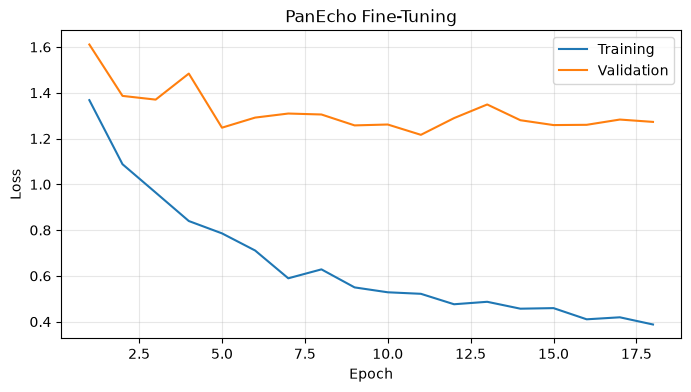

In [19]:
# Plot training and validation loss
history_df = pd.DataFrame(history)
plt.figure(figsize=(8, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Training")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PanEcho Fine-Tuning")
plt.grid(alpha=0.3)
plt.legend()
plt.show()